# Self-Organizing Maps (SOMs) Notebook - Alaska Cyclones
- Plot scatter plot of precipiation and wave heights to see compound impacts at each of the four villages

**Notebook by Alice DuVivier - August 2026**

In [1]:
import pandas as pd
import xarray as xr
import cftime
import numpy as np
import pandas as pd
from itertools import product
import cartopy
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
from datetime import timedelta
from itertools import product
import cmocean
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.ticker as mtick
import math

## Set villages and node of choice

In [2]:
# set node info - '2a'
village_node = '2a'

In [3]:
# set paired lists name and node of interest
village_names = ['Nome','Savoonga','Gambell','Shishmaref','Unalakleet']
village_lats =  [64.501, 63.694, 63.776, 66.257, 63.879]
village_lons =  [-165.406, -170.479, -171.701, -166.072, -160.790]

# set xloc and yloc values - determined from another notebook finding nearest atmospheric point that is over mostly ocean
village_xlocs_atm = [57,55,55,65,55]
village_ylocs_atm = [98,78,73,95,115]

village_xlocs_ice = [261,238,237,289,263]
village_ylocs_ice = [270,234,224,254,310]

nvillages  = len(village_names)
print(nvillages)

5


## Load data
- not identical to training data so we can see larger area patterns

In [4]:
# set path where the som finalist files are
dir_in = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/DATA/SOM_alaska_cyclones/data_for_single_node/'

In [5]:
# choose data - load 10m wind
var_in = 'U10'
# Load data for larger area than only training area - set file name
fin_training = var_in+'_autumn_node_'+village_node+'_alaska_cam_grid'

# load data
ds = xr.open_dataset(dir_in+fin_training+'.nc')

# explicitly load data so that it doesn't take forever later on during mean
ds = ds.load()

# keep this data
data = ds[var_in]
u10 = data

In [6]:
# choose data - load zonal wind first
var_in = 'PRECT'
# Load data for larger area than only training area - set file name
fin_training = var_in+'_autumn_node_'+village_node+'_alaska_cam_grid'

# load data
ds = xr.open_dataset(dir_in+fin_training+'.nc')

# explicitly load data so that it doesn't take forever later on during mean
ds = ds.load()

# keep this data
data = ds[var_in]
precip = data

In [7]:
# set atmosphere lat/lons
lat1d = ds.lat
lon1d = ds.lon

## Break Data into decades

In [8]:
# choose subset of decades to do initial analysis
decades = [1950,2000,2050]
decades_str = ['1950','2000','2050']

In [9]:
# data for each decade in subset of decades
mask_1950 = ds.time.where(ds.decades == 1950)
u10_1950 = u10.where(mask_1950 >= 0, drop=True)
precip_1950 = precip.where(mask_1950 >= 0, drop=True)
print('number of times in 1950:'+str(len(u10_1950.time)))

mask_2000 = ds.time.where(ds.decades == 2000)
u10_2000 = u10.where(mask_2000 >= 0, drop=True)
precip_2000 = precip.where(mask_2000 >= 0, drop=True)
print('number of times in 2000:'+str(len(u10_2000.time)))

mask_2050 = ds.time.where(ds.decades == 2050)
u10_2050 = u10.where(mask_2050 >= 0, drop=True)
precip_2050 = precip.where(mask_2050 >= 0, drop=True)
print('number of times in 2050:'+str(len(u10_2050.time)))

number of times in 1950:198
number of times in 2000:270
number of times in 2050:303


## Get data at villages
- need to loop through each village for each decade

### Atmosphere - U10

In [10]:
## 1950
data_in = u10_1950

# preallocate array
ntime = len(data_in.time)
data_array = np.zeros([nvillages,ntime])

# loop through each year to get the data
for index, vv in enumerate(village_names):
    #print(vv)
    # read in xloc and yloc for this village
    xloc = village_xlocs_atm[index]
    yloc = village_ylocs_atm[index]
    # keep data at this grid point only
    temp = data_in.isel(lat=slice(xloc,xloc+1),lon=slice(yloc,yloc+1))
    data_array[index,:] = temp.isel(lat=0,lon=0)

# convert the numpy arrays to xarrays for easier plotting
u10_villages_1950 = xr.DataArray(data_array,dims=('villages','times'))
u10_villages_1950['villages'] = village_names

In [11]:
## 2000
data_in = u10_2000

# preallocate array
ntime = len(data_in.time)
data_array = np.zeros([nvillages,ntime])

# loop through each year to get the data
for index, vv in enumerate(village_names):
    #print(vv)
    # read in xloc and yloc for this village
    xloc = village_xlocs_atm[index]
    yloc = village_ylocs_atm[index]
    # keep data at this grid point only
    temp = data_in.isel(lat=slice(xloc,xloc+1),lon=slice(yloc,yloc+1))
    data_array[index,:] = temp.isel(lat=0,lon=0)

# convert the numpy arrays to xarrays for easier plotting
u10_villages_2000 = xr.DataArray(data_array,dims=('villages','times'))
u10_villages_2000['villages'] = village_names

In [12]:
## 2050
data_in = u10_2050

# preallocate array
ntime = len(data_in.time)
data_array = np.zeros([nvillages,ntime])

# loop through each year to get the data
for index, vv in enumerate(village_names):
    #print(vv)
    # read in xloc and yloc for this village
    xloc = village_xlocs_atm[index]
    yloc = village_ylocs_atm[index]
    # keep data at this grid point only
    temp = data_in.isel(lat=slice(xloc,xloc+1),lon=slice(yloc,yloc+1))
    data_array[index,:] = temp.isel(lat=0,lon=0)

# convert the numpy arrays to xarrays for easier plotting
u10_villages_2050 = xr.DataArray(data_array,dims=('villages','times'))
u10_villages_2050['villages'] = village_names

### Atmosphere - PRECIP

In [13]:
## 1950
data_in = precip_1950

# preallocate array
ntime = len(data_in.time)
data_array = np.zeros([nvillages,ntime])

# loop through each year to get the data
for index, vv in enumerate(village_names):
    #print(vv)
    # read in xloc and yloc for this village
    xloc = village_xlocs_atm[index]
    yloc = village_ylocs_atm[index]
    # keep data at this grid point only
    temp = data_in.isel(lat=slice(xloc,xloc+1),lon=slice(yloc,yloc+1))
    data_array[index,:] = temp.isel(lat=0,lon=0)

# convert the numpy arrays to xarrays for easier plotting
precip_villages_1950 = xr.DataArray(data_array,dims=('villages','times'))
precip_villages_1950['villages'] = village_names

In [14]:
## 2000
data_in = precip_2000

# preallocate array
ntime = len(data_in.time)
data_array = np.zeros([nvillages,ntime])

# loop through each year to get the data
for index, vv in enumerate(village_names):
    #print(vv)
    # read in xloc and yloc for this village
    xloc = village_xlocs_atm[index]
    yloc = village_ylocs_atm[index]
    # keep data at this grid point only
    temp = data_in.isel(lat=slice(xloc,xloc+1),lon=slice(yloc,yloc+1))
    data_array[index,:] = temp.isel(lat=0,lon=0)

# convert the numpy arrays to xarrays for easier plotting
precip_villages_2000 = xr.DataArray(data_array,dims=('villages','times'))
precip_villages_2000['villages'] = village_names

In [15]:
## 2050
data_in = precip_2050

# preallocate array
ntime = len(data_in.time)
data_array = np.zeros([nvillages,ntime])

# loop through each year to get the data
for index, vv in enumerate(village_names):
    #print(vv)
    # read in xloc and yloc for this village
    xloc = village_xlocs_atm[index]
    yloc = village_ylocs_atm[index]
    # keep data at this grid point only
    temp = data_in.isel(lat=slice(xloc,xloc+1),lon=slice(yloc,yloc+1))
    data_array[index,:] = temp.isel(lat=0,lon=0)

# convert the numpy arrays to xarrays for easier plotting
precip_villages_2050 = xr.DataArray(data_array,dims=('villages','times'))
precip_villages_2050['villages'] = village_names

## Count instances above some thresholds
- Using some absolute thresholds rather than some fraction above decadeal mean since it is the extreme events that matter. There could be a debate of if the threshold should shift with changing mean state, but a 30mph event will impact people whether it's above the normal or not. People impacts are absolute, not relative.
- This plot is to find **COMPOUND** impacts, so we want to find instances where it is above BOTH the significant wave height and precipitation threshold

### Thresholds

Wind speed
- **14m/s = 31.1mph (near gale)**
- Note that these are **DAILY MEAN** wind speeds, not gusts. So gusts could be substantially higher.
- Over open water or flat, smooth terrain, gusts usually measure about 40% higher than the average (https://www.bom.gov.au/resources/learn-and-explore/marine-knowledge-centre/wind-gusts-and-squalls)

Precipitation
- **1.27 cm/day = 0.5 in/day**

In [16]:
# set thresholds
thresh_ws = 14.0
thresh_precip = 1.27

In [17]:
## 1950
data_1 = u10_villages_1950
data_2 = precip_villages_1950

# preallocate array
ntime = len(data_1.times)
data_array = np.zeros([nvillages])

# loop through each village to get the data
for index, vv in enumerate(village_names):
    #print(vv)
    data_sub_1 = data_1.isel(villages=index)
    data_sub_2 = data_2.isel(villages=index)
    # get data that is above the threshold
    sub1 = data_sub_2.where((data_sub_1 > thresh_ws),drop=True)
    sub2 = sub1.where((sub1 > thresh_precip),drop=True)
    count=len(sub2) 
    # save raw number of counts
    data_array[index] = count

# convert the numpy arrays to xarrays for easier plotting
count_compound_villages_1950 = xr.DataArray(data_array,dims=('villages'))
count_compound_villages_1950['villages'] = village_names

In [18]:
## 2000
data_1 = u10_villages_2000
data_2 = precip_villages_2000

# preallocate array
ntime = len(data_1.times)
data_array = np.zeros([nvillages])

# loop through each village to get the data
for index, vv in enumerate(village_names):
    #print(vv)
    data_sub_1 = data_1.isel(villages=index)
    data_sub_2 = data_2.isel(villages=index)
    # get data that is above the threshold
    sub1 = data_sub_2.where((data_sub_1 > thresh_ws),drop=True)
    sub2 = sub1.where((sub1 > thresh_precip),drop=True)
    count=len(sub2) 
    # save raw number of counts
    data_array[index] = count

# convert the numpy arrays to xarrays for easier plotting
count_compound_villages_2000 = xr.DataArray(data_array,dims=('villages'))
count_compound_villages_2000['villages'] = village_names

In [19]:
## 2050
data_1 = u10_villages_2050
data_2 = precip_villages_2050

# preallocate array
ntime = len(data_1.times)
data_array = np.zeros([nvillages])

# loop through each village to get the data
for index, vv in enumerate(village_names):
    #print(vv)
    data_sub_1 = data_1.isel(villages=index)
    data_sub_2 = data_2.isel(villages=index)
    # get data that is above the threshold
    sub1 = data_sub_2.where((data_sub_1 > thresh_ws),drop=True)
    sub2 = sub1.where((sub1 > thresh_precip),drop=True)
    count=len(sub2) 
    # save raw number of counts
    data_array[index] = count

# convert the numpy arrays to xarrays for easier plotting
count_compound_villages_2050 = xr.DataArray(data_array,dims=('villages'))
count_compound_villages_2050['villages'] = village_names

In [20]:
# print these differences
print('Counts with extreme compound impacts')
print('1950')
print(count_compound_villages_1950.values)
print('2000')
print(count_compound_villages_2000.values)
print('2050')
print(count_compound_villages_2050.values)
print(village_names)

Counts with extreme compound impacts
1950
[18.  1.  5.  0.  4.]
2000
[35.  7.  9.  3.  5.]
2050
[41.  8.  6.  5.  6.]
['Nome', 'Savoonga', 'Gambell', 'Shishmaref', 'Unalakleet']


## Plot wind and wave height distributions villages

In [21]:
# set output directory
dir_out = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/SOM_alaska_cyclones/analysis_v4/'

In [22]:
# set colors 
ch1 = 'blue' 
ch2 = 'gold' #'mediumorchid'
ch3 = 'red'

### Plot scatter plot distributions

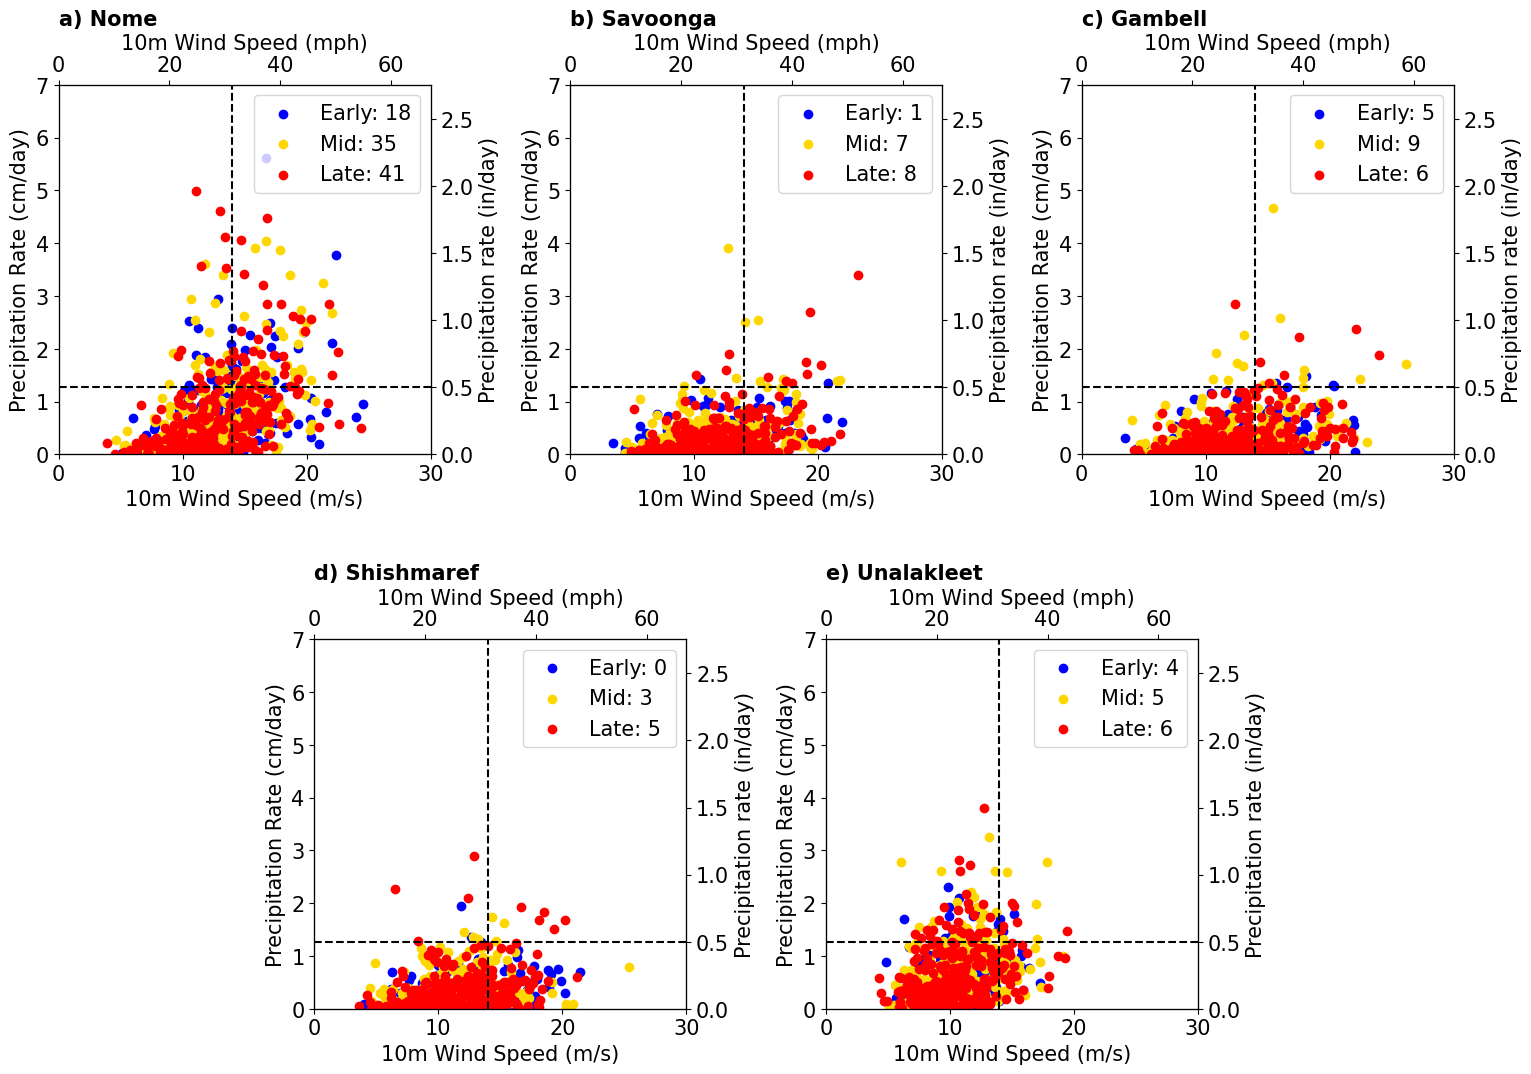

In [28]:
fout = 'figure_9_node_'+village_node+'_compound_impacts_scatter_decadal'

# unit conversions
cm_to_in = 0.393701
mps_to_mph = 2.23694

panel_letters = ['a', 'b', 'c', 'd', 'e']

fig = plt.figure(figsize=(18, 12))
gs = fig.add_gridspec(2, 6, wspace=1.2, hspace=0.5)
# 3 panels on top, 2 centered on the bottom
panel_slots = [gs[0, 0:2], gs[0, 2:4], gs[0, 4:6], gs[1, 1:3], gs[1, 3:5]]

for n in range(5):
    ax = fig.add_subplot(panel_slots[n])
    # get data for x and y axes
    x_data = [u10_villages_1950, u10_villages_2000, u10_villages_2050]
    y_data = [precip_villages_1950, precip_villages_2000, precip_villages_2050]
    counts = [count_compound_villages_1950, count_compound_villages_2000, count_compound_villages_2050]
    colors = [ch1, ch2, ch3]
    period_names = ['Early', 'Mid', 'Late']

    # scatter plot for each period
    for xd, yd, cnt, col, name in zip(x_data, y_data, counts, colors, period_names):
        ax.scatter(xd.isel(villages=n), yd.isel(villages=n), color=col,
                   label=name+': '+str(int(cnt.isel(villages=n).values)))

    # modify plot
    ax.axhline(y=thresh_precip, color='black', linestyle='--')
    ax.axvline(x=thresh_ws, color='black', linestyle='--')
    ax.set_title(panel_letters[n]+') '+village_names[n], loc='left', fontsize=15, fontweight='bold')
    ax.set_xlabel('10m Wind Speed (m/s)', fontsize=15)
    ax.set_ylabel('Precipitation Rate (cm/day)', fontsize=15)
    ax.set_ylim([0, 7])
    ax.set_xlim([0, 30])
    ax.tick_params(labelsize=15)

    # secondary y-axis in in/day
    ax2 = ax.twinx()
    ymin, ymax = ax.get_ylim()
    ax2.set_ylim(ymin * cm_to_in, ymax * cm_to_in)
    ax2.set_ylabel('Precipitation rate (in/day)', fontsize=15)
    ax2.tick_params(axis='y', labelsize=15)
    
    # secondary x-axis in mph or ft
    ax3 = ax.twiny()
    xmin, xmax = ax.get_xlim()
    ax3.set_xlim(xmin * mps_to_mph, xmax * mps_to_mph)
    ax3.set_xlabel('10m Wind Speed (mph)', fontsize=15)
    ax3.tick_params(axis='x', labelsize=15)

    # add legend
    ax.legend(fontsize=15, loc='upper right')

# save figure
fig.savefig(fout+'.png', bbox_inches='tight', dpi=200)
fig.savefig(dir_out+fout+'.png', bbox_inches='tight', dpi=200)